# 京都大学 2026 理系 第2問 — Julia + Wolfram Engine で解く

## 問題

$r$ は正の実数とする。1 辺の長さが $1$ の正四面体 $\mathrm{OABC}$ において，辺 $\mathrm{OA}$ 上に点 $\mathrm{P}$ をとる。点 $\mathrm{P}$ が辺 $\mathrm{OA}$ 上のどこにあっても，点 $\mathrm{P}$ を中心とする半径 $r$ の球面が，辺 $\mathrm{BC}$ と共有点をもたないような $r$ の範囲を求めよ。ただし，点 $\mathrm{O}$，$\mathrm{A}$ は辺 $\mathrm{OA}$ に含まれ，点 $\mathrm{B}$，$\mathrm{C}$ は辺 $\mathrm{BC}$ に含まれるとする。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。

In [1]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. 座標を設定する

$\mathrm{O}$ を原点，$\mathrm{A}$ を $x$ 軸上，$\mathrm{B}$ を $xy$ 平面上（$y > 0$）にとります。

$$\mathrm{O}(0,\ 0,\ 0),\qquad \mathrm{A}(1,\ 0,\ 0),\qquad \mathrm{B}\left(\tfrac12,\ \tfrac{\sqrt3}{2},\ 0\right)$$

$\mathrm{C}(x,\ y,\ z)$ は，$\mathrm{OC} = \mathrm{AC} = \mathrm{BC} = 1$，$z > 0$ を満たす点として `Solve` で求めます。

In [2]:
Ow = W`{0, 0, 0}`
Aw = W`{1, 0, 0}`
Bw = W`{1/2, Sqrt[3]/2, 0}`

# 点の座標を ( , , ) の形で表示する（Wolfram のリストは { } で表示されるため）
ptex(w) = replace(tex(w), "\\left\\{" => "\\left(", "\\right\\}" => "\\right)", "\\{" => "(", "\\}" => ")")

dist2(p, q) = W"Dot"(W"Subtract"(p, q), W"Subtract"(p, q))      # 2 点間の距離の 2 乗（Wolfram の式）

Xw = W`{x, y, z}`
Cw = weval(W"ReplaceAll"(Xw, W"First"(W"Solve"(
        W"List"(W"Equal"(dist2(Xw, Ow), 1), W"Equal"(dist2(Xw, Aw), 1), W"Equal"(dist2(Xw, Bw), 1), W`z > 0`), Xw))))
showtex("\\mathrm{C} = " * ptex(Cw))

6 本の辺の長さがすべて $1$ になっていることを確かめます。

In [3]:
pts = ["O" => Ow, "A" => Aw, "B" => Bw, "C" => Cw]
edges = [(i, j) for i in 1:4 for j in i+1:4]
showtex(join(["\\mathrm{$(pts[i][1])$(pts[j][1])} = " * tex(weval(W"Simplify"(W"Sqrt"(dist2(pts[i][2], pts[j][2]))))) for (i, j) in edges], ",\\quad "))

## 2. 点 $\mathrm{P}$ を媒介変数で表す

$\mathrm{P}$ は線分 $\mathrm{OA}$ 上の点なので，媒介変数 $t$（$0 \leqq t \leqq 1$）を使って

$$\overrightarrow{\mathrm{OP}} = (1 - t)\,\overrightarrow{\mathrm{OO}} + t\,\overrightarrow{\mathrm{OA}} = t\,\overrightarrow{\mathrm{OA}}$$

と表せます。$t = 0$ で $\mathrm{O}$，$t = 1$ で $\mathrm{A}$ です（両端を含む）。

In [4]:
Pw = weval(W"Plus"(W"Times"(W`1 - t`, Ow), W"Times"(W"t", Aw)))
showtex("\\mathrm{P} = " * ptex(Pw) * "\\qquad (0 \\leqq t \\leqq 1)")

### Julia に持ってきて図にする

頂点の座標を Julia のベクトルに，$\mathrm{P}$ を $t$ の関数にします。

In [5]:
O, A, B, C = (Float64.(to_value(w)) for w in (Ow, Aw, Bw, Cw))      # Julia のベクトル
P = to_function(Pw, :t)                                             # Julia の関数 P(t)

@show B C
@show P(0) P(0.3) P(1);

B = [0.5, 0.8660254037844386, 0.0]
C = [0.5, 0.2886751345948129, 0.816496580927726]
P(0) = [0, 0, 0]
P(0.3) = [0.3, 0.0, 0.0]
P(1) = [1, 0, 0]


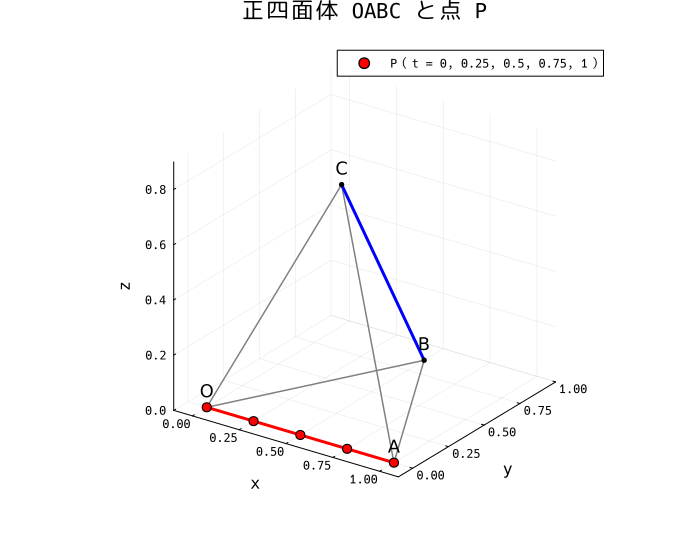

In [6]:
seg!(p, U, V; kw...) = plot!(p, [U[1], V[1]], [U[2], V[2]], [U[3], V[3]]; label="", kw...)      # 線分 UV をかく

p = plot(; xlabel="x", ylabel="y", zlabel="z", camera=(35, 25), aspect_ratio=:equal, size=(680, 560),
         xlims=(-0.1, 1.1), ylims=(-0.1, 1.0), zlims=(0, 0.9), title="正四面体 OABC と点 P", legend=:topright)
for (U, V) in [(O, B), (O, C), (A, B), (A, C)]
    seg!(p, U, V; color=:gray, lw=1.5)
end
seg!(p, O, A; color=:red,  lw=3)       # 辺 OA（P が動く）
seg!(p, B, C; color=:blue, lw=3)       # 辺 BC
for (V, name) in [(O, "O"), (A, "A"), (B, "B"), (C, "C")]
    scatter!(p, [V[1]], [V[2]], [V[3]]; color=:black, markersize=3, label="")
    annotate!(p, V[1], V[2], V[3] + 0.06, text(name, 12))
end
ts = 0:0.25:1
Ps = Float64.(stack(P.(ts)))           # 列が P(t)
scatter!(p, Ps[1, :], Ps[2, :], Ps[3, :]; color=:red, markersize=5, label="P（t = 0, 0.25, 0.5, 0.75, 1）")

赤が辺 $\mathrm{OA}$（$\mathrm{P}$ が動く辺），青が辺 $\mathrm{BC}$ です。

## 3. 球面と辺 $\mathrm{BC}$ が共有点をもたない境界を調べる

### 考え方

辺 $\mathrm{BC}$ 上の点を $\mathrm{Q}$ とします。$\mathrm{Q}$ が辺 $\mathrm{BC}$ 上を動くとき，距離 $\mathrm{PQ}$ は連続に変わるので，その最小値を $d_{\min}$，最大値を $d_{\max}$ とすると，

- 球面が辺 $\mathrm{BC}$ と共有点をもつ $\iff$ $d_{\min} \leqq r \leqq d_{\max}$
- 共有点をもたない $\iff$ $r < d_{\min}$（辺 $\mathrm{BC}$ 全体が球の**外側**）または $r > d_{\max}$（辺 $\mathrm{BC}$ 全体が球の**内部**）

です。$d_{\min}$ には直線 $\mathrm{BC}$ との距離（垂線の足が辺の上にあるかどうか）が，$d_{\max}$ には端点 $\mathrm{B}$，$\mathrm{C}$ との距離が関わります。

### $\mathrm{Q}$ を媒介変数で表し，$\mathrm{PQ}^2$ を計算する

$\overrightarrow{\mathrm{OQ}} = (1 - s)\,\overrightarrow{\mathrm{OB}} + s\,\overrightarrow{\mathrm{OC}}$（$0 \leqq s \leqq 1$）とします。

In [7]:
Qw = weval(W"Simplify"(W"Plus"(W"Times"(W`1 - s`, Bw), W"Times"(W"s", Cw))))
showtex("\\mathrm{Q} = " * ptex(Qw) * "\\qquad (0 \\leqq s \\leqq 1)")

d2w = weval(W"Expand"(dist2(Pw, Qw)))      # PQ² を s, t の式で
showtex("\\mathrm{PQ}^2 = " * tex(d2w))

$\mathrm{PQ}^2$ は $s$ の 2 次式（$s^2$ の係数が正）で，しかも $s$ の部分と $t$ の部分がきれいに分かれています。

### 直線 $\mathrm{BC}$ との距離（最小値 $d_{\min}$）

$s$ で微分して $0$ になる $s$（$\mathrm{P}$ から直線 $\mathrm{BC}$ に下ろした垂線の足）を求めます。

In [8]:
s0w = weval(W"ReplaceAll"(W"s", W"First"(W"Solve"(W"Equal"(W"D"(d2w, W"s"), 0), W"s"))))      # 垂線の足の s
near2w = weval(W"Expand"(W"ReplaceAll"(d2w, W"Rule"(W"s", s0w))))                             # そのときの PQ²
showtex("s = " * tex(s0w) * ",\\qquad d_{\\min}^{\\,2} = " * tex(near2w))

垂線の足は $t$ によらず $s = \dfrac12$，つまりいつも辺 $\mathrm{BC}$ の**中点**です。$0 \leqq s \leqq 1$ の範囲に入っているので，直線 $\mathrm{BC}$ との距離がそのまま辺 $\mathrm{BC}$ との最短距離 $d_{\min}$ になります（端点が最短になる場合は起こらない）。

### 端点との距離（最大値 $d_{\max}$）

$s$ の 2 次式で下に凸なので，最大値は端点 $s = 0$（$\mathrm{B}$）か $s = 1$（$\mathrm{C}$）でとります。

In [9]:
PB2w = weval(W"Expand"(W"ReplaceAll"(d2w, W"Rule"(W"s", 0))))
PC2w = weval(W"Expand"(W"ReplaceAll"(d2w, W"Rule"(W"s", 1))))
showtex("\\mathrm{PB}^2 = " * tex(PB2w) * ",\\qquad \\mathrm{PC}^2 = " * tex(PC2w))
far2w = PB2w;      # d_max²

$\mathrm{PB} = \mathrm{PC}$ です（$\mathrm{P}$ は辺 $\mathrm{BC}$ の垂直二等分面の上にある）。したがって $d_{\max} = \mathrm{PB} = \mathrm{PC}$。

### $t$ を動かしたときの境界

$\mathrm{P}$ が辺 $\mathrm{OA}$ 上を動く（$0 \leqq t \leqq 1$）ときの，$d_{\min}$ の最小値と $d_{\max}$ の最大値を求めます。

In [10]:
dom = W`0 <= t <= 1`
lo = weval(W"Minimize"(W"List"(W"Sqrt"(near2w), dom), W"t"))      # {最小値, {t -> ...}}
hi = weval(W"MaxValue"(W"List"(W"Sqrt"(far2w), dom), W"t"))       # 最大値
hit = weval(W"ReplaceAll"(W"t", W"Solve"(W"And"(W"Equal"(far2w, W"Power"(hi, 2)), dom), W"t")))      # 最大になる t

showtex("d_{\\min}\\ \\text{の最小値} = " * tex(lo.args[1]) * "\\quad \\left(t = " * tex(lo.args[2].args[1].args[2]) * "\\right)")
showtex("d_{\\max}\\ \\text{の最大値} = " * tex(hi) * "\\quad \\left(t = " * join(tex.(hit.args), ",\\ ") * "\\right)")

### $(t,\ r)$ 平面で見る

$d_{\min}$，$d_{\max}$ を $t$ の Julia の関数にして，横軸 $t$，縦軸 $r$ の図にします。2 本の曲線にはさまれた帯が「共有点をもつ」部分です。

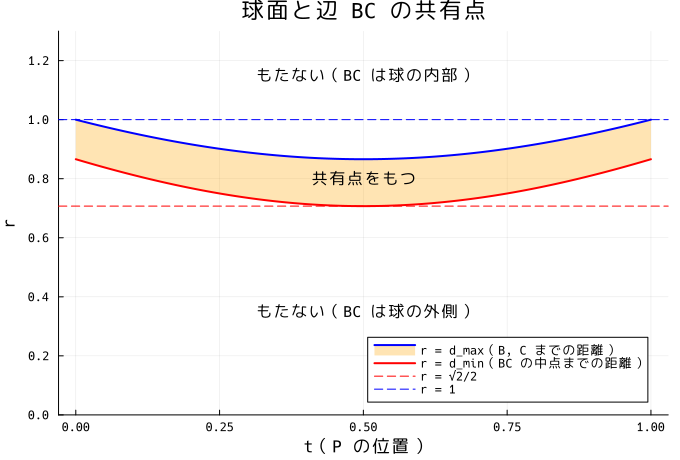

In [11]:
dmin = to_function(weval(W"Sqrt"(near2w)), :t)
dmax = to_function(weval(W"Sqrt"(far2w)), :t)
rlo, rhi = to_value(lo.args[1]), to_value(hi)

tv = range(0, 1; length=200)
plot(tv, dmax.(tv); fillrange=dmin.(tv), fillalpha=0.3, fillcolor=:orange, lw=2, color=:blue,
     label="r = d_max（B, C までの距離）", xlabel="t（P の位置）", ylabel="r", ylims=(0, 1.3), size=(680, 460),
     legend=:bottomright, title="球面と辺 BC の共有点")
plot!(tv, dmin.(tv); lw=2, color=:red, label="r = d_min（BC の中点までの距離）")
hline!([rlo]; color=:red,  ls=:dash, label="r = √2/2")
hline!([rhi]; color=:blue, ls=:dash, label="r = 1")
jtext(str) = text(str, 10, "cica")      # 図の中の日本語（注釈は既定のフォントにならないので指定する）
annotate!(0.5, 0.80, jtext("共有点をもつ"))
annotate!(0.5, 0.35, jtext("もたない（BC は球の外側）"))
annotate!(0.5, 1.15, jtext("もたない（BC は球の内部）"))

### 分かったこと

- **下の境界**（赤）：$d_{\min} = \sqrt{t^2 - t + \dfrac34}$。$t = \dfrac12$（$\mathrm{P}$ が $\mathrm{OA}$ の中点）で最小値 $\dfrac{\sqrt2}{2}$。これは向かい合う辺 $\mathrm{OA}$ と $\mathrm{BC}$ の中点どうしの距離です。
- **上の境界**（青）：$d_{\max} = \sqrt{t^2 - t + 1}$。$t = 0,\ 1$（$\mathrm{P}$ が $\mathrm{O}$ または $\mathrm{A}$）で最大値 $1$（正四面体の 1 辺）。
- 「$\mathrm{P}$ がどこにあっても共有点をもたない」ためには，水平線 $r = $ 一定 が帯にまったく触れなければよいので，点線より下（$r < \dfrac{\sqrt2}{2}$）か，点線より上（$r > 1$）になりそうです。境界の値 $r = \dfrac{\sqrt2}{2}$，$r = 1$ では帯に触れる（共有点をもつ $t$ がある）ので含みません。

## 4. $r$ の範囲を求める

### 3 節の結果から

$\mathrm{P}$ の位置 $t$ を決めたとき，球面が辺 $\mathrm{BC}$ と共有点をもつ $r$ の範囲は

$$\sqrt{t^2 - t + \tfrac34} \leqq r \leqq \sqrt{t^2 - t + 1}$$

です。$t$ が $0 \leqq t \leqq 1$ を動くと，この区間は連続的に動き，左端の最小値は $\dfrac{\sqrt2}{2}$，右端の最大値は $1$ なので，区間全体を合わせると $\dfrac{\sqrt2}{2} \leqq r \leqq 1$ になります。つまり

- $\dfrac{\sqrt2}{2} \leqq r \leqq 1$ のとき：共有点をもつような $\mathrm{P}$ の位置が**ある**
- それ以外のとき：$\mathrm{P}$ がどこにあっても共有点をもたない

まず，$t$ を決めたときの $r$ の範囲を Wolfram で確かめます（「$\mathrm{PQ} = r$ となる $s$ が $0 \leqq s \leqq 1$ に存在する」を `Exists` で書いて `Reduce`）。

In [12]:
# 論理記号を日本語にする
jtex(str) = replace(str, "\\lor" => "\\ \\ \\text{または}\\ \\ ", "\\land" => "\\ \\text{かつ}\\ ")

meet = W"Exists"(W"s", W`0 <= s <= 1`, W"Equal"(d2w, W`r^2`))      # 共有点をもつ：PQ² = r² となる s がある
r1 = weval(W"Reduce"(W"And"(meet, W`r > 0`, dom), W"r", W"Reals"))
showtex("\\text{共有点をもつ} \\iff " * jtex(tex(r1)))

### 「どこにあっても共有点をもたない」を Wolfram で直接解く

問題文の条件をそのまま書きます：「すべての $t$（$0 \leqq t \leqq 1$）について，共有点をもたない」。`ForAll` と `Exists` を使って `Reduce` します。

In [13]:
never = W"ForAll"(W"t", dom, W"Not"(meet))      # どの t でも共有点をもたない
answ = weval(W"Reduce"(W"And"(never, W`r > 0`), W"r", W"Reals"))
showtex(jtex(tex(answ)))

### 検算：Julia で距離を直接計算する

式を使わずに，Julia のベクトル `P(t)`，`B`，`C` から距離 $\mathrm{PQ}$ を細かい格子で計算し，「共有点をもつ $t$ があるか」を調べます。Wolfram の答えを Julia の判定関数にしたもの（`ok(r)`）と比べます。

In [14]:
using LinearAlgebra

ok = to_function(answ, :r)                         # Wolfram の答え → Julia の判定関数（true：条件を満たす）

Q(s) = (1 - s) * B + s * C                         # 辺 BC 上の点
sg = range(0, 1; length=401)
tg = range(0, 1; length=401)
function meets(r)                                  # 共有点をもつ t があるか（格子で調べる）
    any(tg) do t
        d = [norm(P(t) - Q(s)) for s in sg]
        minimum(d) <= r <= maximum(d)
    end
end

for r in [0.3, 0.7, 0.7071, 0.7072, 0.8, 0.9, 1.0, 1.0001, 1.2]
    println(rpad("r = $r", 12), "共有点をもつ P が", meets(r) ? "ある　" : "ない　", "   Wolfram の答え：", ok(r) ? "条件を満たす" : "満たさない")
end

r = 0.3     共有点をもつ P がない　   Wolfram の答え：条件を満たす
r = 0.7     共有点をもつ P がない　   Wolfram の答え：条件を満たす
r = 0.7071  共有点をもつ P がない　   Wolfram の答え：条件を満たす
r = 0.7072  共有点をもつ P がある　   Wolfram の答え：満たさない
r = 0.8     共有点をもつ P がある　   Wolfram の答え：満たさない
r = 0.9     共有点をもつ P がある　   Wolfram の答え：満たさない
r = 1.0     共有点をもつ P がある　   Wolfram の答え：満たさない
r = 1.0001  共有点をもつ P がない　   Wolfram の答え：条件を満たす
r = 1.2     共有点をもつ P がない　   Wolfram の答え：条件を満たす


$\dfrac{\sqrt2}{2} = 0.70710\cdots$ と $1$ を境に，判定が一致しています。

## 答え

$$0 < r < \frac{\sqrt2}{2} \quad \text{または} \quad r > 1$$

- $r < \dfrac{\sqrt2}{2}$：球が小さく，辺 $\mathrm{BC}$ に届かない（$\dfrac{\sqrt2}{2}$ は辺 $\mathrm{OA}$ と辺 $\mathrm{BC}$ の中点どうしの距離）
- $r > 1$：球が大きく，辺 $\mathrm{BC}$ 全体が球の内部に入る（$1$ は頂点 $\mathrm{O}$，$\mathrm{A}$ から $\mathrm{B}$，$\mathrm{C}$ までの距離）